# 01 · Panorama: como é o tráfego de cada sensor?  🟢 *fácil*

Antes de comparar sensores entre si, precisamos conhecer **cada um**: quanto recebe, de quem, em que portas,
com que tipo de pacote. São contagens e rankings simples — mas cheios de armadilhas de interpretação.

**Perguntas deste notebook**

1. Quanto tráfego cada sensor recebe por dia? E quantas **origens distintas**?
2. Quais **protocolos** e **portas** são mais procurados? Muda de sensor para sensor?
3. Quanto é **varredura** e quanto é **backscatter**?
4. De quais **países** e **organizações (ASN)** vem o tráfego? O ranking depende de *como* contamos?
5. O tráfego é **concentrado** em poucas origens?

**Ferramentas de pandas usadas:** `groupby`, `value_counts`, `pivot_table`, `crosstab`, `nunique`.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# A pasta raiz da série (onde estão os .py). Funciona tanto na raiz quanto em solucoes/.
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "solucoes" else os.getcwd()
sys.path.insert(0, RAIZ)
import holoscope_io as hio
import holoscope_ana as ha
ha.estilo()

# >>> Para usar os DADOS REAIS, troque só esta linha pela pasta dos parquet <<<
PASTA = os.path.join(RAIZ, "dados_sinteticos")
if not os.path.isdir(PASTA):   # primeira vez: gera os dados fictícios (~20 s)
    import subprocess
    subprocess.run([sys.executable, os.path.join(RAIZ, "gerar_sintetico_real.py"), "--saida", PASTA], check=True)

In [2]:
df = hio.carregar_holoscope(PASTA, extras=("asn", "geo", "app"))
df["flags"] = hio.flags_texto(df["tcp_flags"]).astype("category")
SENS = sorted(df["sensor"].unique())
COR = ha.cores(SENS)          # cor fixa por sensor, igual em todos os gráficos
df.head(3)

83 arquivos | 6 sensores (worker) | 2026-09-01 a 2026-09-14 | 2,024,894 pacotes | 107 MB na memória
origens reservadas/privadas descartadas: 35,000


,ts,sensor,site,src_ip,dst_ip,src_port,dst_port,transport_proto,tcp_flags,app_proto,asn,asn_rede,asn_org,continente,pais,pais_nome,lat,lon,flags
0,2026-09-01 00:00:05.337532866+00:00,ifes-worker-00,ifes,577773216,3323073570,60749,2323,TCP,2,TELNET,64827,34.112.0.0/16,Broadband Exemplo 315 (IR),Asia,IR,Iran,32.0,53.0,S
1,2026-09-01 00:00:07.290313692+00:00,ifes-worker-00,ifes,577773216,3323073781,60749,8080,TCP,2,HTTP,64827,34.112.0.0/16,Broadband Exemplo 315 (IR),Asia,IR,Iran,32.0,53.0,S
2,2026-09-01 00:00:10.787767942+00:00,ufes-worker-00,ufes,887696972,3323071011,25,56532,TCP,18,SMTP,64721,52.233.0.0/16,Hosting Exemplo 209 (CN),Asia,CN,China,35.0,105.0,SA


## 1. Volume por sensor e por dia

Duas medidas diferentes, que contam histórias diferentes:

* **pacotes** — quanto "barulho" chegou;
* **IPs de origem distintos** — quantas **máquinas** diferentes mandaram algo.

Um único scanner agressivo pode gerar milhares de pacotes; mil máquinas mandando 1 pacote cada geram mil.

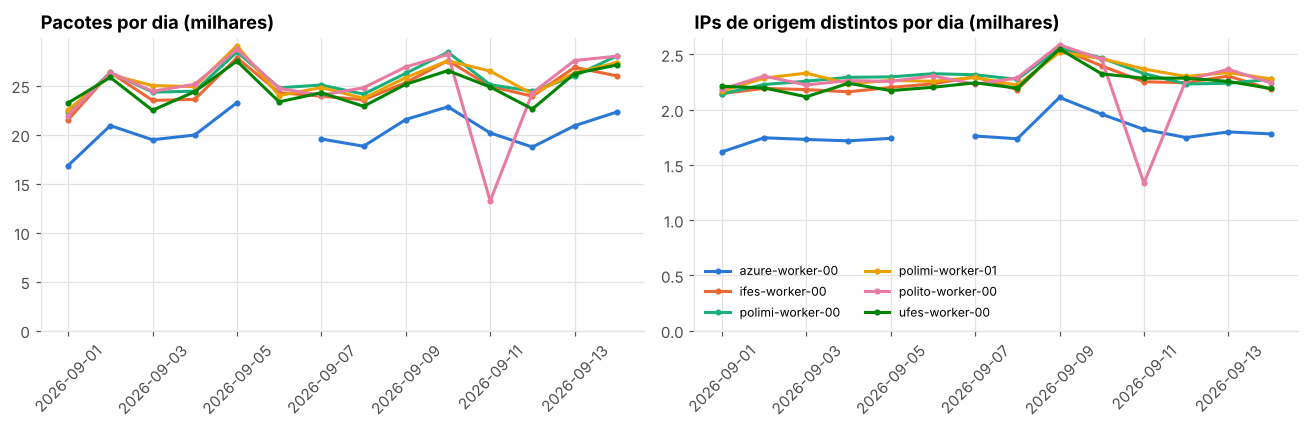

In [3]:
df["dia"] = df["ts"].dt.floor("D")
por_dia = df.groupby(["dia", "sensor"], observed=True).agg(pacotes=("src_ip", "size"),
                                                          ips=("src_ip", "nunique"))
pac = por_dia["pacotes"].unstack()
ips = por_dia["ips"].unstack()

# dia sem arquivo deve ser NaN (não 0). Reindexamos para todos os dias do período:
dias = pd.date_range(df["dia"].min(), df["dia"].max(), freq="D", tz="UTC")
pac, ips = pac.reindex(dias), ips.reindex(dias)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for s in SENS:
    axs[0].plot(pac.index, pac[s] / 1000, marker="o", ms=3, color=COR[s], label=s)
    axs[1].plot(ips.index, ips[s] / 1000, marker="o", ms=3, color=COR[s], label=s)
axs[0].set_title("Pacotes por dia (milhares)")
axs[1].set_title("IPs de origem distintos por dia (milhares)")
for a in axs:
    a.set_ylim(bottom=0)
    a.tick_params(axis="x", rotation=45)
axs[1].legend(loc="lower left", fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Como ler:** as linhas são parecidas (os sensores recebem volumes da mesma ordem), mas:

* a linha do `azure-worker-00` **interrompe** num dia — é o arquivo que falta (veja o notebook 00). Como usamos
  `NaN`, o gráfico mostra um **buraco**, e não uma queda falsa a zero;
* outro sensor tem um dia com **metade** do volume. Queda de coleta ou o mundo mudou? Pista: os outros sensores
  não caíram no mesmo dia.

> ⚠️ **Armadilha:** concluir "o sensor X é menos atacado" a partir de totais, sem descontar dias de coleta.
> Compare **médias por dia com dados**, não somas.

In [4]:
tabela = pd.DataFrame({
    "dias com dados": pac.notna().sum(),
    "pacotes/dia (média)": pac.mean().round(0),
    "IPs/dia (média)": ips.mean().round(0),
    "pacotes por IP": (pac.sum() / df.groupby("sensor", observed=True)["src_ip"].nunique()).round(1),
}).sort_values("pacotes/dia (média)", ascending=False)
tabela

,dias com dados,pacotes/dia (média),IPs/dia (média),pacotes por IP
sensor,,,,
polimi-worker-00,14,25572.0,2302.0,33.3
polimi-worker-01,14,25555.0,2308.0,33.1
ifes-worker-00,14,24938.0,2252.0,33.0
polito-worker-00,14,24872.0,2236.0,32.9
ufes-worker-00,14,24746.0,2247.0,33.0
azure-worker-00,13,20410.0,1789.0,29.9


## 2. Protocolos e portas

* **TCP** é usado para serviços com conexão (SSH, HTTP, Telnet…). Um scanner manda um **SYN** e espera a resposta.
* **UDP** é sem conexão (DNS, NTP, SNMP…). Alguns servem para **amplificação** de DDoS, por isso são varridos.
* **ICMP** é o "ping".

A **porta de destino** diz **qual serviço** o scanner procura.

In [5]:
proto = pd.crosstab(df["sensor"], df["transport_proto"], normalize="index").mul(100).round(1)
proto

transport_proto,TCP,UDP,ICMP
sensor,,,
azure-worker-00,89.8,8.6,1.6
ifes-worker-00,89.4,8.9,1.7
polimi-worker-00,88.9,9.4,1.7
polimi-worker-01,89.3,8.8,1.8
polito-worker-00,89.1,9.2,1.7
ufes-worker-00,89.3,9.1,1.5


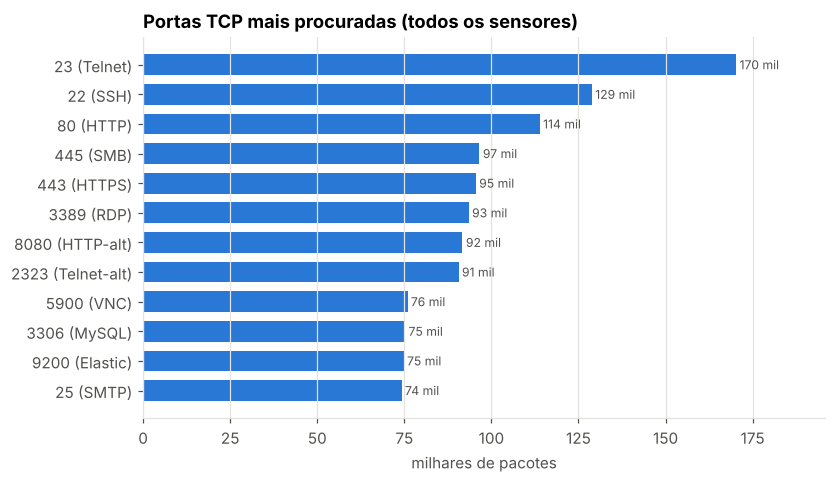

In [6]:
NOMES = {22: "SSH", 23: "Telnet", 80: "HTTP", 443: "HTTPS", 445: "SMB", 3389: "RDP", 8080: "HTTP-alt",
         2323: "Telnet-alt", 5900: "VNC", 6379: "Redis", 1433: "MSSQL", 3306: "MySQL", 53: "DNS",
         123: "NTP", 161: "SNMP", 1900: "SSDP", 2375: "Docker", 9200: "Elastic", 21: "FTP", 25: "SMTP"}

def nome_porta(p):
    return f"{p} ({NOMES[p]})" if p in NOMES else str(p)

tcp = df[df["transport_proto"] == "TCP"]
top = tcp["dst_port"].value_counts().head(12)
fig, ax = plt.subplots(figsize=(8, 4.5))
ha.barras_h(top.rename(index=nome_porta) / 1000, ax=ax, fmt="{:,.0f} mil",
            titulo="Portas TCP mais procuradas (todos os sensores)", xlabel="milhares de pacotes")
plt.show()

O ranking geral pode esconder diferenças entre sensores. Um **mapa de calor** porta × sensor, com a
**porcentagem do tráfego TCP de cada sensor**, mostra se algum sensor é "especial":

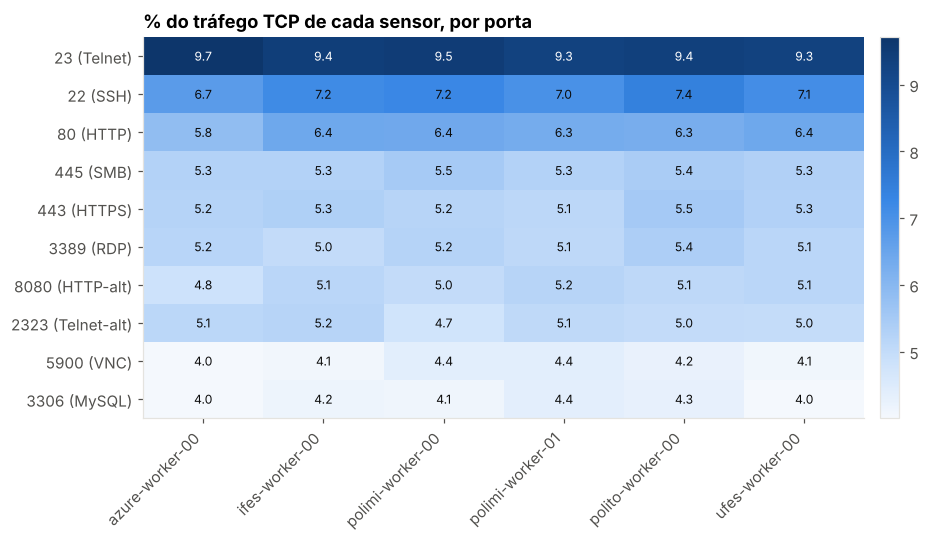

In [7]:
portas = top.index[:10]
M = (pd.crosstab(tcp["dst_port"], tcp["sensor"], normalize="columns").loc[portas] * 100)
fig, ax = plt.subplots(figsize=(9, 4.5))
ha.heatmap(M.rename(index=nome_porta), ax=ax, fmt="{:.1f}", titulo="% do tráfego TCP de cada sensor, por porta")
plt.show()

**Leitura:** as colunas são parecidas — a maioria dos scanners varre a internet **inteira**, então todo sensor
vê mais ou menos a mesma mistura de portas. Diferenças grandes numa linha seriam uma pista interessante
(um sensor visado? um bloco de IP com histórico?).

### ✏️ TODO 1 — Portas UDP

Repita o ranking para **UDP**: guarde em `resp_1` uma `Series` com as **5 portas UDP** mais frequentes
(índice = porta, valor = nº de pacotes) e faça o gráfico de barras com `ha.barras_h`.

<details><summary><b>Dica</b> (clique)</summary>

Filtre `df["transport_proto"] == "UDP"` e use `value_counts().head(5)`.

</details>

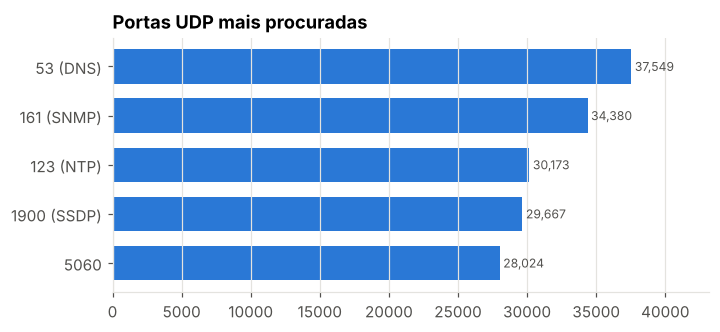

In [8]:
# SOLUÇÃO
resp_1 = df.loc[df["transport_proto"] == "UDP", "dst_port"].value_counts().head(5)
fig, ax = plt.subplots(figsize=(7, 3))
ha.barras_h(resp_1.rename(index=nome_porta), ax=ax, titulo="Portas UDP mais procuradas")
plt.show()

In [9]:
# Verificação (não precisa mexer)
if resp_1 is None:
    print("⏳ TODO 1 ainda não resolvido")
else:
    assert len(resp_1) == 5 and resp_1.is_monotonic_decreasing
    assert resp_1.index[0] == df.loc[df["transport_proto"] == "UDP", "dst_port"].mode()[0]
    print("✅ TODO 1 ok:", list(resp_1.index))

✅ TODO 1 ok: [53, 161, 123, 1900, 5060]


## 3. Varredura × backscatter: as flags TCP

| flags | quem manda | o que significa |
|---|---|---|
| `S` (SYN) | scanner | "tem alguém na porta X?" |
| `SEC` (SYN + ECN) | scanner com pilha de SO moderna | mesma coisa |
| `SA` (SYN-ACK) | **vítima** de DDoS | "sim, estou aqui" — resposta a um SYN **forjado** com nosso endereço |
| `R`, `RA` (RST) | **vítima** de DDoS | "não, porta fechada" — idem |

Num SYN-ACK/RST, o IP de origem **não é o atacante**: é a **vítima** respondendo. É por isso que backscatter
precisa ser **separado** antes de falar em "quem varre".

In [10]:
fl = pd.crosstab(df["sensor"], df["flags"]).drop(columns="", errors="ignore")
(fl.div(fl.sum(axis=1), axis=0) * 100).round(2)

flags,R,RA,S,SA,SEC
sensor,,,,,
azure-worker-00,1.20,1.99,85.24,4.75,6.81
ifes-worker-00,0.92,1.60,85.40,3.78,8.30
polimi-worker-00,0.93,1.53,85.30,3.68,8.55
polimi-worker-01,0.92,1.53,85.58,3.63,8.34
polito-worker-00,0.90,1.45,85.80,3.62,8.24
ufes-worker-00,0.99,1.62,85.23,3.77,8.39


### ✏️ TODO 2 — Fração de backscatter por sensor

Calcule em `resp_2` uma `Series` (índice = sensor) com a **fração** (0 a 1) dos pacotes **TCP** de cada sensor
que são backscatter, isto é, com flags `SA`, `R` ou `RA`.

<details><summary><b>Dica</b> (clique)</summary>

Crie uma coluna booleana `df["flags"].isin(["SA", "R", "RA"])` dentro do subconjunto TCP e faça
`groupby("sensor", observed=True).mean()`.

</details>

In [11]:
# SOLUÇÃO
t = df[df["transport_proto"] == "TCP"]
resp_2 = t["flags"].isin(["SA", "R", "RA"]).groupby(t["sensor"], observed=True).mean()
resp_2.sort_values()

sensor
polito-worker-00    0.060114
polimi-worker-01    0.061281
polimi-worker-00    0.061995
ifes-worker-00      0.063455
ufes-worker-00      0.064216
azure-worker-00     0.079944
Name: flags, dtype: float64

In [12]:
# Verificação (não precisa mexer)
if resp_2 is None:
    print("⏳ TODO 2 ainda não resolvido")
else:
    assert set(resp_2.index) == set(SENS) and resp_2.between(0, 1).all()
    assert 0.001 < resp_2.mean() < 0.2
    print("✅ TODO 2 ok — média", f"{resp_2.mean():.2%}")

✅ TODO 2 ok — média 6.52%


## 4. De onde vem: países e organizações (ASN)

Um **ASN** (*Autonomous System Number*) identifica uma rede administrada por **uma** organização: um provedor
de internet, uma nuvem, uma universidade. É um nível de agregação mais estável que o IP.

**Pergunta-chave:** o ranking muda se contarmos **pacotes** ou **IPs distintos**?

In [13]:
scan = df[~df["flags"].isin(["SA", "R", "RA"])]   # só varredura (sem backscatter)
paises = pd.DataFrame({"pacotes": scan["pais"].value_counts(),
                       "ips": scan.groupby("pais", observed=True)["src_ip"].nunique()})
paises["pacotes por IP"] = (paises["pacotes"] / paises["ips"]).round(1)
paises["rank pacotes"] = paises["pacotes"].rank(ascending=False).astype(int)
paises["rank IPs"] = paises["ips"].rank(ascending=False).astype(int)
paises.sort_values("pacotes", ascending=False).head(10)

,pacotes,ips,pacotes por IP,rank pacotes,rank IPs
pais,,,,,
US,382466,6194,61.7,1,1
IN,243614,4994,48.8,2,2
CN,239465,4884,49.0,3,3
IT,178038,3366,52.9,4,4
DE,138909,1513,91.8,5,8
BR,111046,2215,50.1,6,5
NL,100879,1843,54.7,7,6
FR,82200,1775,46.3,8,7
HK,68542,1340,51.2,9,9


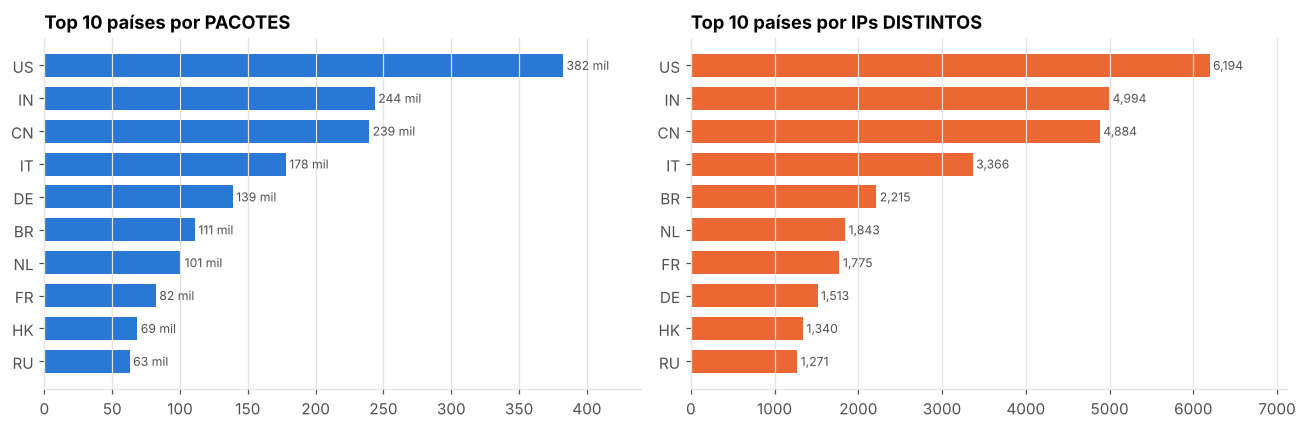

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
ha.barras_h(paises["pacotes"].nlargest(10) / 1000, ax=axs[0], fmt="{:,.0f} mil", titulo="Top 10 países por PACOTES")
ha.barras_h(paises["ips"].nlargest(10), ax=axs[1], cor=ha.PALETA[1], titulo="Top 10 países por IPs DISTINTOS")
plt.tight_layout(); plt.show()

**Leitura:** os rankings não são iguais. Países com **muitos IPs e poucos pacotes por IP** sugerem muitas máquinas
pequenas (ex.: dispositivos infectados de uma botnet); países com **poucos IPs e muitos pacotes por IP** sugerem
poucos servidores varrendo muito (ex.: serviços de varredura em datacenters).

> ⚠️ **Armadilha:** "o país X ataca mais". Geolocalização indica onde o **IP está registrado**, não quem está por
> trás. Uma máquina invadida no país X pode ser controlada de qualquer lugar.

In [15]:
orgs = (scan.groupby(["asn", "asn_org"], observed=True)
            .agg(pacotes=("src_ip", "size"), ips=("src_ip", "nunique"), sensores=("sensor", "nunique"))
            .sort_values("pacotes", ascending=False))
orgs.head(10)

,,pacotes,ips,sensores
asn,asn_org,,,
64512,Cloud Exemplo 000 (IN),152267,2937,6
64513,Broadband Exemplo 001 (IT),97517,1721,6
65400,Varredura Academica Exemplo A,62419,40,6
65401,Varredura Academica Exemplo B,62010,40,6
64514,Broadband Exemplo 002 (FR),60201,1208,6
64515,Broadband Exemplo 003 (US),55309,914,6
64516,Broadband Exemplo 004 (US),41986,818,6
64517,Telecom Exemplo 005 (IT),39165,669,6
64518,Cloud Exemplo 006 (CN),30637,566,6


### ✏️ TODO 3 — Top ASNs por número de IPs

Monte em `resp_3` a tabela dos **10 ASNs com mais IPs distintos** (só varredura, use `scan`), com as colunas
`asn`, `asn_org`, `ips` e `pacotes`, ordenada por `ips`. Compare com a tabela acima: quais organizações aparecem
em uma e não na outra?

<details><summary><b>Dica</b> (clique)</summary>

Reaproveite `orgs`: basta `orgs.sort_values("ips", ascending=False).head(10).reset_index()`.

</details>

In [16]:
# SOLUÇÃO
resp_3 = orgs.sort_values("ips", ascending=False).head(10).reset_index()[["asn", "asn_org", "ips", "pacotes"]]
resp_3

,asn,asn_org,ips,pacotes
0,64512,Cloud Exemplo 000 (IN),2937,152267
1,64513,Broadband Exemplo 001 (IT),1721,97517
2,64514,Broadband Exemplo 002 (FR),1208,60201
3,64515,Broadband Exemplo 003 (US),914,55309
4,64516,Broadband Exemplo 004 (US),818,41986
5,64517,Telecom Exemplo 005 (IT),669,39165
6,64518,Cloud Exemplo 006 (CN),566,30637
7,64520,Broadband Exemplo 008 (HK),526,29934
8,64519,Telecom Exemplo 007 (SG),461,24241
9,64521,Telecom Exemplo 009 (BR),418,24125


In [17]:
# Verificação (não precisa mexer)
if resp_3 is None:
    print("⏳ TODO 3 ainda não resolvido")
else:
    assert len(resp_3) == 10 and {"asn", "asn_org", "ips", "pacotes"} <= set(resp_3.columns)
    assert resp_3["ips"].is_monotonic_decreasing
    print("✅ TODO 3 ok. Só em pacotes:",
          sorted(set(orgs.head(10).reset_index()["asn_org"]) - set(resp_3["asn_org"]))[:4])

✅ TODO 3 ok. Só em pacotes: ['Varredura Academica Exemplo A', 'Varredura Academica Exemplo B']


## 5. Concentração: poucos fazem muito barulho?

Em tráfego de internet é comum a **cauda pesada**: a maioria das origens manda pouquíssimo, e umas poucas
mandam muito. A ferramenta certa para ver isso é a **CCDF** em escala **log-log**:
$P(X \ge x)$ = "fração das origens que mandaram pelo menos $x$ pacotes".

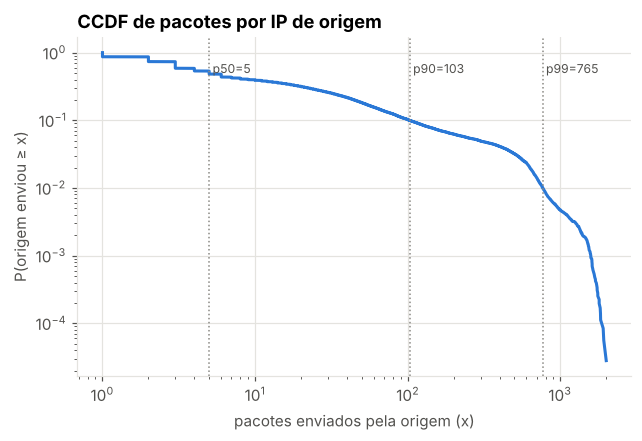

35,692 IPs | mediana 5 pacotes | máximo 1,999


In [18]:
por_ip = scan.groupby("src_ip").size()
x, y = ha.ccdf(por_ip.values)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(x, y, color=ha.PALETA[0])
ax.set_xlabel("pacotes enviados pela origem (x)")
ax.set_ylabel("P(origem enviou ≥ x)")
ax.set_title("CCDF de pacotes por IP de origem")
for q in [0.5, 0.9, 0.99]:
    v = por_ip.quantile(q)
    ax.axvline(v, color=ha.CINZA, lw=1, ls=":")
    ax.text(v, 0.5, f" p{int(q*100)}={v:.0f}", fontsize=8, color=ha.TEXTO2)
plt.show()
print(f"{len(por_ip):,} IPs | mediana {por_ip.median():.0f} pacotes | máximo {por_ip.max():,}")

### ✏️ TODO 4 — Quanto do tráfego vem do 1% mais ativo?

Calcule em `resp_4` a **fração dos pacotes de varredura** enviada pelo **1% de IPs mais ativos**
(número entre 0 e 1). Depois responda em texto (comentário): isso é concentrado?

<details><summary><b>Dica</b> (clique)</summary>

Ordene `por_ip` decrescente, pegue os primeiros `ceil(0.01 * len(por_ip))` e divida a soma deles pelo total.

</details>

In [19]:
# SOLUÇÃO
k = int(np.ceil(0.01 * len(por_ip)))
resp_4 = por_ip.sort_values(ascending=False).head(k).sum() / por_ip.sum()
print(f"o 1% mais ativo ({k} IPs) gerou {resp_4:.1%} dos pacotes")

o 1% mais ativo (357 IPs) gerou 20.5% dos pacotes


In [20]:
# Verificação (não precisa mexer)
if resp_4 is None:
    print("⏳ TODO 4 ainda não resolvido")
else:
    assert 0.01 < resp_4 < 1
    print("✅ TODO 4 ok:", f"{resp_4:.1%}")

✅ TODO 4 ok: 20.5%


## Resumo

* Compare sensores por **média por dia com dados**, nunca por soma bruta.
* **Pacotes** e **IPs distintos** contam histórias diferentes — mostre os dois.
* **Backscatter** (SA/R/RA) é resposta de vítimas: separe antes de falar de "scanners".
* O tráfego tem **cauda pesada**: use CCDF log-log e reporte concentração (top 1%).

## Desafios (sem solução)

1. **`app_proto` × porta.** Monte `pd.crosstab(df["dst_port"], df["app_proto"])` para as 20 portas mais comuns.
   Quando a porta e o "protocolo de aplicação" discordam? O que isso diz sobre como `app_proto` foi calculado?
2. **Continentes.** Repita a tabela de países agregando por `continente`. Algum continente aparece mais nos sensores
   brasileiros do que nos italianos? (Guarde a pergunta: ela volta no notebook 02.)
3. **Pacotes por IP por sensor.** A CCDF tem o mesmo formato em todos os sensores? Desenhe uma curva por sensor
   (use as cores de `COR`).
4. **Índice de Gini.** Pesquise o que é e calcule-o para `por_ip`. Compare com a fração do top 1%.